# CNN Classification on Tom and Jerry Dataset
**Student ID:** 23-51626-2  |  **Course:** CVPR  |  **Assignment:** CNN Development on Custom Dataset

**Objective:** Design, train and evaluate a custom CNN that classifies Tom & Jerry cartoon frames into 4 classes.

The pipeline (data loading, augmentation, CNN, training/validation functions, training loop, plots, test evaluation, single-image prediction) is the same as the Cat & Dog example notebook shared in class.Only the dataset-related parts differ, plus I chose 64×64 for more detail.

**Notebook structure:** 1. Import Libraries → 2. Load & Explore Dataset → 3. Preprocessing & Augmentation → 4. CNN Architecture → 5. Training → 6. Test Evaluation → 7. Visualizations → 8. Analysis & Discussion → 9. Conclusions & Future Work

## 1. Import Libraries

In [ ]:
!pip install -q torchsummary kagglehub scikit-learn

from torchvision import datasets
import torchvision.transforms as transforms

from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

# (added) fixed seeds so the results can be reproduced
import os, random
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

cpu


## 2. Load and Explore Dataset

**Dataset:** Tom and Jerry Image Classification (Kaggle, `balabaskar/tom-and-jerry-image-classification`).

- 5,478 frames extracted at 1 FPS from the Tom & Jerry cartoon and labelled manually.
- **4 classes** (one folder each): `jerry` (only Jerry), `tom` (only Tom), `tom_jerry_1` (both characters), `tom_jerry_0` (neither character).
- Colour frames of different sizes, so they are resized to a fixed size.
- The dataset also has `ground_truth.csv` and `challenges.csv` (distorted frames). The folder names already give the labels, so `ImageFolder` is used (as in the Cat & Dog example).
- The images are inside `<path>/tom_and_jerry/tom_and_jerry/<class>/`. If `ImageFolder` is pointed one folder higher it sees only **one** class, so the full path is used below.
- Unlike the Cat & Dog dataset, there is no ready-made train/test split, so the data is split randomly into train / validation / test in the next section.

In [ ]:
import kagglehub
path = kagglehub.dataset_download("balabaskar/tom-and-jerry-image-classification")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'tom-and-jerry-image-classification' dataset.
Path to dataset files: /kaggle/input/tom-and-jerry-image-classification


## 3. Data Preprocessing & Augmentation

- **Resize to 64×64:** the CNN needs a fixed input size (the class example uses 32×32; 64×64 keeps more detail of the small characters while still training quickly on CPU).
- **Augmentation (training only):** random horizontal flip, rotation ±15°, colour jitter (same as the class example) to reduce overfitting.
- **Validation / test:** only resize + `ToTensor`, so evaluation is done on unmodified images (two `ImageFolder` objects over the same files).
- **Split:** 70% train / 15% validation / 15% test, random with a fixed seed (42).

In [ ]:
import torchvision.transforms as transforms
from torch.utils.data import Subset

size = 64
train_transform = transforms.Compose([
    transforms.Resize((size, size)),        # resize to model input size
    transforms.RandomHorizontalFlip(),    # horizontal flip augmentation
    transforms.RandomRotation(15),        # rotate ±15 degrees
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()                # convert PIL → float tensor [0.0,1.0]
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

data_folder = path + '/tom_and_jerry/tom_and_jerry'

train_dataset    = datasets.ImageFolder(data_folder, transform = train_transform)  # with augmentation
val_test_dataset = datasets.ImageFolder(data_folder, transform = val_transform)    # without augmentation

# Split dataset into Train (70%), Validation (15%) and Test (15%)
total = len(train_dataset)
train_size = int(0.7 * total)
val_size = int(0.15 * total)
test_size = total - train_size - val_size

perm = torch.randperm(total, generator=torch.Generator().manual_seed(42)).tolist()
train_data = Subset(train_dataset,    perm[:train_size])
val_data   = Subset(val_test_dataset, perm[train_size:train_size + val_size])
test_data  = Subset(val_test_dataset, perm[train_size + val_size:])

class_names = train_dataset.classes
num_classes = len(class_names)


In [ ]:
print('Dataset Summary')
print('Train Data: ', len(train_data))
print('Validation Data: ', len(val_data))
print('Test Data: ', len(test_data))
print('Classess and Indices: ' , train_dataset.class_to_idx)
print('Number of classes: ', num_classes)

Dataset Summary
Train Data:  3834
Validation Data:  821
Test Data:  823
Classess and Indices:  {'jerry': 0, 'tom': 1, 'tom_jerry_0': 2, 'tom_jerry_1': 3}
Number of classes:  4


train {'jerry': 870, 'tom': 1345, 'tom_jerry_0': 1070, 'tom_jerry_1': 549}
val   {'jerry': 186, 'tom': 279, 'tom_jerry_0': 237, 'tom_jerry_1': 119}
test  {'jerry': 184, 'tom': 306, 'tom_jerry_0': 221, 'tom_jerry_1': 112}


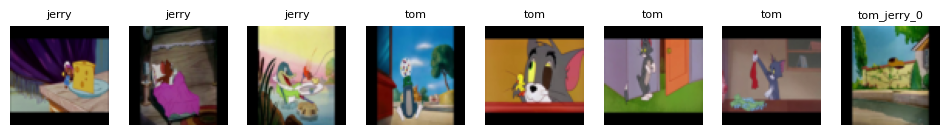

In [ ]:
# (added) class distribution and a few sample images
targets = np.array(train_dataset.targets)
for name, idx in [("train", perm[:train_size]),
                  ("val  ", perm[train_size:train_size + val_size]),
                  ("test ", perm[train_size + val_size:])]:
    print(name, dict(zip(class_names, np.bincount(targets[idx], minlength=num_classes).tolist())))

plt.figure(figsize=(12, 3))
for i in range(8):
    img, lbl = val_test_dataset[i * 500]
    plt.subplot(1, 8, i + 1)
    plt.imshow(img.permute(1, 2, 0)); plt.title(class_names[lbl], fontsize=8); plt.axis("off")
plt.show()

## 3b. Hyperparameters and rationale

| Hyperparameter | Value | Why |
|---|---|---|
| Image size | 64×64 | More detail than 32×32 for small characters, still fast on CPU |
| Batch size | 32 | Stable gradient estimates, small memory use |
| Learning rate | 1e-3 | Standard starting value for Adam |
| Epochs | 10 |Same as the class example|
| Optimizer | Adam | Adaptive learning rate, fast convergence |
| Loss | CrossEntropyLoss | Multi-class classification (4 classes) |
| Augmentation | flip, rotation ±15°, colour jitter | Reduces overfitting (training set only) |
| Split | 70 / 15 / 15 random | Large train set, equal validation and test sets |
| Seed | 42 | Reproducible split and results |

In [ ]:
batch_size = 32
learning_rate=1e-3
epoch_number = 10

In [ ]:
trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

## 4. Define CNN Architecture

The same two-block CNN as the Cat & Dog class example, with only the input size and the number of outputs adapted:

- **Block 1:** `Conv2d(3→64, 3×3)` → `ReLU` → `MaxPool2d(2)`  (64×64 → 62×62 → 31×31). Learns low-level features such as edges and colours.
- **Block 2:** `Conv2d(64→128, 3×3)` → `ReLU` → `MaxPool2d(2)`  (31×31 → 29×29 → 14×14). Learns higher-level shapes (ears, face, body).
- **Classifier:** `Flatten` (128·14·14 = 25,088) → `Linear(25,088→256)` → `ReLU` → `Linear(256→4)`. The 4 outputs are class scores (logits); `CrossEntropyLoss` applies softmax internally.
- In the class example (32×32 input, 2 classes) the first linear layer has 128·6·6 inputs and the last layer 2 outputs. Here they are 128·14·14 and 4.
- Total trainable parameters: 6,499,460 (about 26 MB when saved).

In [ ]:
from torch.optim import SGD, Adam
def get_model():
    model = nn.Sequential(
        #Feature Extraction
        nn.Conv2d(3, 64, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(64, 128, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),

        #Classifier
        nn.Flatten(),
        nn.Linear(128*14*14, 256),
        nn.ReLU(),
        nn.Linear(256, num_classes)
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

In [ ]:
!pip install -q torchsummary
from torchsummary import summary
model, loss_fn, optimizer = get_model()
summary(model, input_size=(3,size,size));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 62, 62]           1,792
              ReLU-2           [-1, 64, 62, 62]               0
         MaxPool2d-3           [-1, 64, 31, 31]               0
            Conv2d-4          [-1, 128, 29, 29]          73,856
              ReLU-5          [-1, 128, 29, 29]               0
         MaxPool2d-6          [-1, 128, 14, 14]               0
           Flatten-7                [-1, 25088]               0
            Linear-8                  [-1, 256]       6,422,784
              ReLU-9                  [-1, 256]               0
           Linear-10                    [-1, 4]           1,028
Total params: 6,499,460
Trainable params: 6,499,460
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.05
Forward/backward pass size (MB): 6.25
Params size (MB): 24.79
Estima

## 5. Training Loop with Validation

`train_one_epoch` does the forward pass, loss, backpropagation and an Adam step for every batch. `validation` evaluates without gradients (`@torch.no_grad`, `model.eval()`). The training loop runs for 10 epochs and stores loss/accuracy of every epoch for plotting.

In [ ]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)   # move to device here
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

In [ ]:
## Training Loop ###
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(epoch_number):
  epoch_loss, epoch_accuracy = train_one_epoch(trn_dl,model,loss_fn,optimizer)
  train_losses.append(epoch_loss)
  train_accuracies.append(epoch_accuracy)

  v_loss, v_acc =  validation(val_dl,model,loss_fn)
  val_losses.append(v_loss)
  val_accuracies.append(v_acc)

  print(f"Epoch [{epoch + 1}/{epoch_number}]"
        f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
        f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

Epoch [1/10] | Train Loss: 1.3467 | Train Accuracy: 34.51% | Val Loss: 1.3087 | Val Accuracy: 34.23%
Epoch [2/10] | Train Loss: 1.2706 | Train Accuracy: 40.71% | Val Loss: 1.2230 | Val Accuracy: 44.21%
Epoch [3/10] | Train Loss: 1.1698 | Train Accuracy: 47.97% | Val Loss: 1.1255 | Val Accuracy: 48.60%
Epoch [4/10] | Train Loss: 1.0539 | Train Accuracy: 54.38% | Val Loss: 0.9737 | Val Accuracy: 58.22%
Epoch [5/10] | Train Loss: 0.9279 | Train Accuracy: 61.50% | Val Loss: 0.8874 | Val Accuracy: 64.19%
Epoch [6/10] | Train Loss: 0.8169 | Train Accuracy: 65.65% | Val Loss: 0.7643 | Val Accuracy: 70.40%
Epoch [7/10] | Train Loss: 0.7122 | Train Accuracy: 71.26% | Val Loss: 0.7885 | Val Accuracy: 68.33%
Epoch [8/10] | Train Loss: 0.6520 | Train Accuracy: 74.99% | Val Loss: 0.7436 | Val Accuracy: 72.23%
Epoch [9/10] | Train Loss: 0.5829 | Train Accuracy: 77.62% | Val Loss: 0.7647 | Val Accuracy: 70.89%
Epoch [10/10] | Train Loss: 0.5474 | Train Accuracy: 79.45% | Val Loss: 0.5972 | Val Accura

### Save the trained model weights
Only the weights (`state_dict`) are saved. The file is larger than 20 MB, so it is **not uploaded to GitHub**; a local copy is kept (as required in the assignment).

In [ ]:
model_filename = "CNN_23_51626_2.pth"
torch.save(model.state_dict(), model_filename)
print(f"Model successfully saved to {model_filename}")
print(f"Saved model size: {os.path.getsize(model_filename) / 1e6:.2f} MB")

# Load it back into a fresh model to check that saving worked
loaded_model, _, _ = get_model()
loaded_model.load_state_dict(torch.load(model_filename, map_location=device))
print("Reloaded model val accuracy:", validation(val_dl, loaded_model, loss_fn)[1] * 100)

Model successfully saved to CNN_23_51626_2.pth
Saved model size: 26.00 MB
Reloaded model val accuracy: 79.29354445797807


## 6. Evaluate Model on Test Set
The trained model is evaluated on the unseen test set: test loss and accuracy, then per-class precision / recall / F1 and a confusion matrix.

In [ ]:
test_loss, test_acc =  validation(test_dl,model,loss_fn)
print(f'Test Loss : {test_loss:0.2f} , Test Accuracy: {test_acc*100:0.2f}%')

Test Loss : 0.64 , Test Accuracy: 76.67%


              precision    recall  f1-score   support

       jerry     0.7234    0.7391    0.7312       184
         tom     0.8017    0.8987    0.8475       306
 tom_jerry_0     0.7196    0.6968    0.7080       221
 tom_jerry_1     0.8462    0.5893    0.6947       112

    accuracy                         0.7667       823
   macro avg     0.7727    0.7310    0.7454       823
weighted avg     0.7682    0.7667    0.7632       823



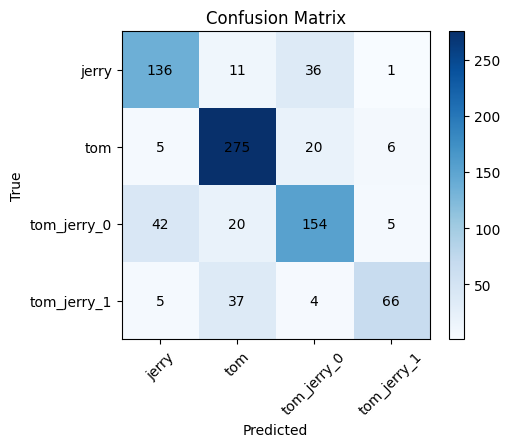

In [ ]:
# (added) per-class metrics and confusion matrix
from sklearn.metrics import classification_report, confusion_matrix

model.eval()
all_preds, all_true = [], []
with torch.no_grad():
    for x, y in test_dl:
        all_preds.extend(model(x.to(device)).argmax(-1).cpu().tolist())
        all_true.extend(y.tolist())

print(classification_report(all_true, all_preds, target_names=class_names, digits=4))

cm = confusion_matrix(all_true, all_preds)
plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(num_classes), class_names, rotation=45); plt.yticks(range(num_classes), class_names)
for i in range(num_classes):
    for j in range(num_classes):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion Matrix")
plt.show()

### Single image prediction with confidence

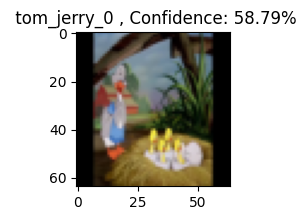

In [ ]:
test_img, label = test_data[2]
img = test_img.view(-1,3,size,size).to(device)

output = model(img)
pred = torch.exp(output)/torch.sum(torch.exp(output))
confidence, index  = pred.max(-1)

plt.figure(figsize=(2,2))
plt.imshow(test_img.view(3,size,size).permute(1,2,0))
plt.title(f' {class_names[index.item()]} , Confidence: {confidence.item()*100:0.2f}%')
plt.show()

## 7. Visualizations (Loss / Accuracy Curves)

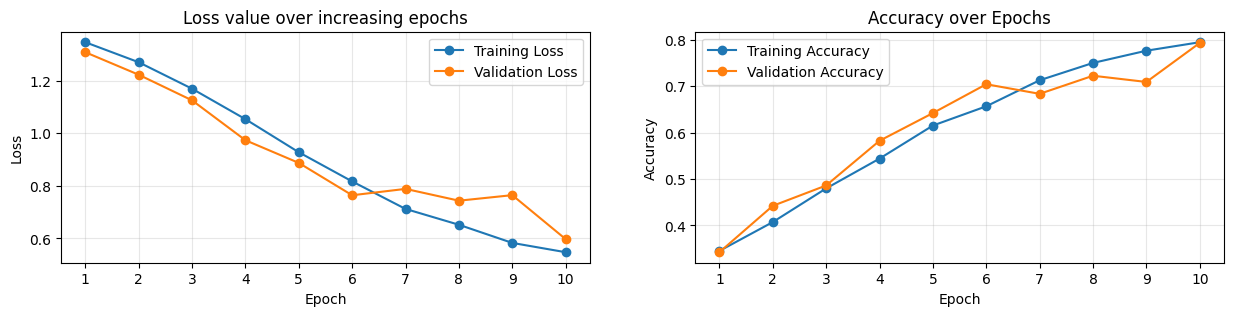

In [ ]:
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 3))
plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Explanation of the curves
- **Loss curve:** Training loss decreases steadily from 1.3467 (epoch 1) to 0.5474 (epoch 10), and validation loss decreases from 1.3087 to 0.5972. The two curves stay close to each other, so the model is learning useful features.
- **Accuracy curve:** Training accuracy rises from 34.51% to 79.45% and validation accuracy from 34.23% to 79.29%. Validation accuracy fluctuates a little in epochs 7-9 (68.33%, 72.23%, 70.89%) because the validation set is small and training is still noisy, then it rises again at epoch 10.
- **Train vs validation gap:** In epochs 2-6 validation accuracy is slightly higher than training accuracy because the training images are augmented while the validation images are not. A small gap appears in epochs 7-9 (for example epoch 9: 77.62% train vs 70.89% validation), but it closes again at epoch 10 (79.45% vs 79.29%). So there is no strong sign of overfitting.
- **Trend at epoch 10:** Both losses are still falling and both accuracies are still rising, so the model is not fully trained yet. More epochs would probably improve the result.validation loss slightly increased at epochs 7 and 9, but dropped to 0.5972 at epoch 10.

## 8. Analysis & Discussion of Results
- **Test accuracy:** 76.67% (test loss 0.64) on 823 unseen images. Macro F1 = 0.7454 and weighted F1 = 0.7632. Random guessing for 4 classes gives about 25%. The test accuracy is a little lower than the validation accuracy at epoch 10 (79.29%), which is expected because they are different images.
- **Per-class results:** `tom` is the best class (precision 0.8017, recall 0.8987, F1 0.8475). `jerry` has F1 0.7312 and `tom_jerry_0` has F1 0.7080. The weakest class is `tom_jerry_1` (F1 0.6947): its precision is high (0.8462) but its recall is only 0.5893, so many images of this class are missed.
- **Confusion matrix:** The biggest confusion is that 37 of 112 `tom_jerry_1` images (about 33%) were predicted as `tom`, which means the model sees Tom but misses Jerry. Also 36 of 184 `jerry` images (about 20%) were predicted as `tom_jerry_0`, and 42 of 221 `tom_jerry_0` images (about 19%) were predicted as `jerry`, so "only Jerry" and "no character" are often mixed up. `tom` is classified correctly in 275 of 306 images (about 90%).
- **Likely reasons for these errors:** Jerry is a small character and probably becomes hard to see at 64x64, so frames with only Jerry may look like frames with no character, and frames with both may look like Tom only. Some frames are dark, blurred or show only part of a character.
- **Class imbalance:** `tom_jerry_1` is the smallest class (549 training images) and has the lowest recall, while `tom` is the largest (1345 training images) and has the highest recall. No class weights were used, so the imbalance probably contributes to these results.
- **Design choices:** The same 2-block CNN as the class example was used. The large flattened feature map (128x14x14) keeps more spatial detail, which probably helps with small characters. Adam converged steadily (apart from a small dip in validation accuracy in epochs 7-9), and augmentation probably helped keep the training and validation curves close to each other.
- **Single image example:** The test image was predicted as `tom_jerry_0` with 58.79% confidence. The frame shows a duck with ducklings and neither Tom nor Jerry is visible, so `tom_jerry_0` ("neither character") looks like the correct class, but the model is only moderately confident.
- **Limitations:** Only 10 epochs, a small CNN without BatchNorm or dropout, 64x64 input, and no handling of class imbalance. Neighbouring 1-FPS frames also look very similar, so train and test images can be alike and the test accuracy may be slightly optimistic.

## 9. Conclusions & Future Work
**Conclusion:** A custom 2-block CNN, trained from scratch for 10 epochs, classified Tom and Jerry frames into 4 classes with 76.67% test accuracy (macro F1 0.7454). Training and validation curves improved together without strong overfitting. The model still confuses Jerry-only frames with frames without characters, and often misses Jerry when both characters are present.

**Future work:** More epochs (the curves were still improving), a larger input size so Jerry is more visible, class weights for the smaller classes, a deeper CNN with BatchNorm and dropout, transfer learning (ResNet / EfficientNet), splitting by scene to avoid near-duplicate frames across splits, and error analysis on the `challenges.csv` images.